P.S. Зображення Orange для завдань 11-13 розташовані у папці в репозиторії та вкінці звіту.


# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Колбасюк Данило'      # прізвище та ім'я
GROUP        = 'ШІ-32'      # шифр групи, наприклад СШІ-31
NUMBER       = 5       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Колбасюк Данило | ШІ-32 | номер 5


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 5   ·   Колбасюк Данило   ·   ШІ-32

   Ринок:  Kirovohrad
   Товар:  сало   (у наборі даних: Fat (salo) - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
import pandas as pd
prices=pd.read_csv('ціни_україна_2014_2017.csv')
prices['date']=pd.to_datetime(dict(year=prices['рік'],month=prices['місяць'],day=1))
grid=pd.date_range('2014-03-01','2017-12-01',freq='MS')
s=(prices[(prices['ринок']==MARKET) & (prices['товар']==GOOD)].sort_values('date').set_index('date')['ціна'])
print(f"Місяців у сітці: {len(grid)}")
print(f"Завантажено спостережень: {len(s)}")
missing=grid.difference(s.index)
print(f"Пропущений місяць: {missing.strftime('%Y-%m').tolist()[0]}")
s




Місяців у сітці: 46
Завантажено спостережень: 45
Пропущений місяць: 2017-08


date
2014-03-01    22.7867
2014-04-01    22.3600
2014-05-01    22.3600
2014-06-01    21.5533
2014-07-01    21.1500
2014-08-01    22.9700
2014-09-01    34.4633
2014-10-01    39.5100
2014-11-01    38.6900
2014-12-01    37.4200
2015-01-01    37.4200
2015-02-01    38.2667
2015-03-01    39.8400
2015-04-01    36.2033
2015-05-01    35.0000
2015-06-01    36.1900
2015-07-01    38.2700
2015-08-01    43.1367
2015-09-01    46.4833
2015-10-01    48.1600
2015-11-01    51.2100
2015-12-01    51.2100
2016-01-01    48.2533
2016-02-01    42.8500
2016-03-01    42.4300
2016-04-01    40.2933
2016-05-01    39.8400
2016-06-01    39.4033
2016-07-01    38.5300
2016-08-01    38.5300
2016-09-01    40.6867
2016-10-01    46.0300
2016-11-01    47.8533
2016-12-01    48.2767
2017-01-01    47.4300
2017-02-01    45.4000
2017-03-01    39.9633
2017-04-01    38.6900
2017-05-01    38.6900
2017-06-01    41.4733
2017-07-01    45.2267
2017-09-01    54.8367
2017-10-01    58.5333
2017-11-01    64.2533
2017-12-01    60.9333
Name:

**Висновок до завдання 1:**
46 місяців у сітці, 45 мають запис
Пропущено серпень 2017 року.
Для серпня 2017 запис у файлі csv відсутній впринципі, це єдиний пропуск у ряді.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
# Завдання 2. Заповнення пропуску
prev_val=s.loc['2017-07-01']
next_val=s.loc['2017-09-01']
ffill=prev_val
linear=(prev_val+next_val)/2
seasonal=s.loc['2016-08-01']
print("Перенесення:", ffill)
print("Лінійна інтерполяція:", linear)
print("Сезонне (значення з попереднього року):", seasonal)
# Обираю лінійну інтерполяцію
s=s[~s.index.duplicated(keep='first')]
s=s.reindex(grid)
s.loc['2017-08-01']=linear
print(s.loc['2017-08-01'])


Перенесення: 45.2267
Лінійна інтерполяція: 50.0317
Сезонне (значення з попереднього року): 38.53
50.0317


**Висновок до завдання 2:**
Перенесення - 45.2267, лінійна інтерполяція - 50.0317, сезонне - 38.53.
Обрав лінійну інтерполяцію, сезонне не врахуває значення 2017 року, а перенесення може не врахувати можливу сезонність.
Якщо даних не існувало, пропуск заповнити неможливо. Наприклад, для Луганської та Донецької областей в цей рік ринку як такого не було декілька місяців.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

C:\Users\JustDector\AppData\Local\Temp\ipykernel_22608\1949812760.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


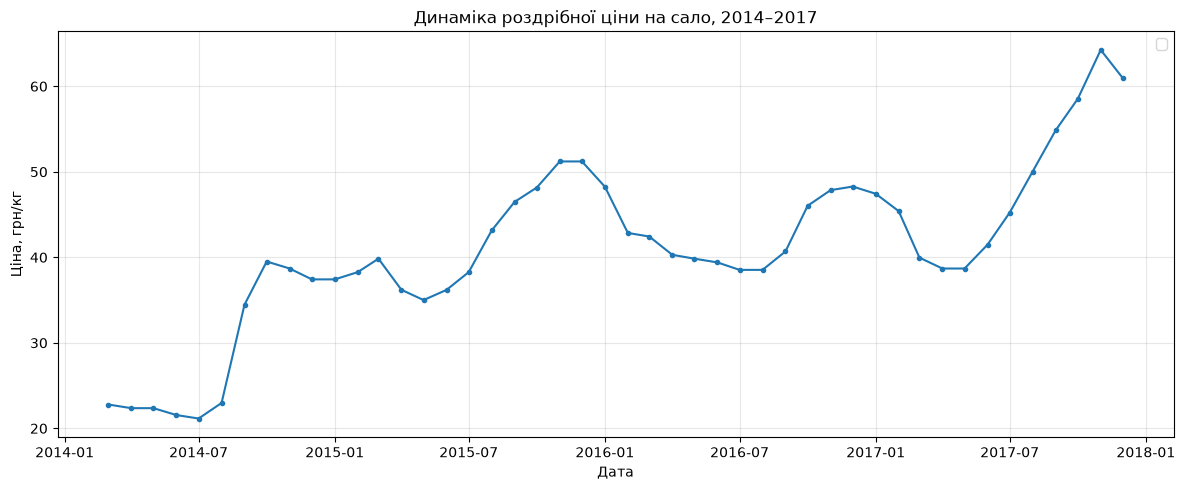

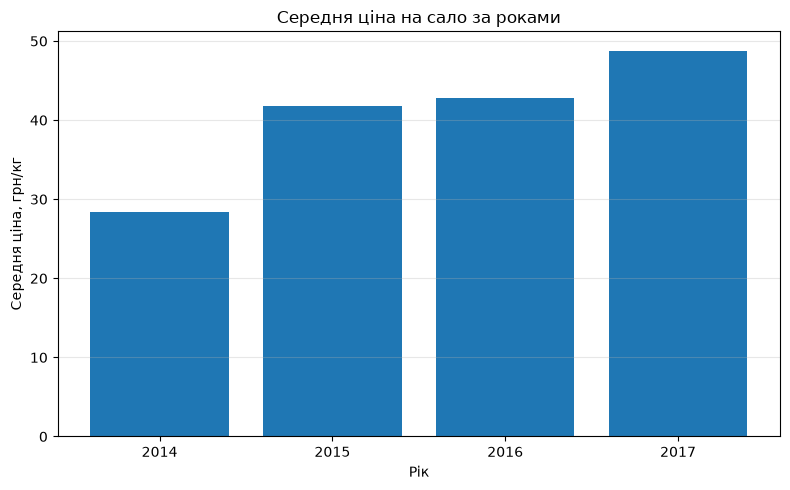

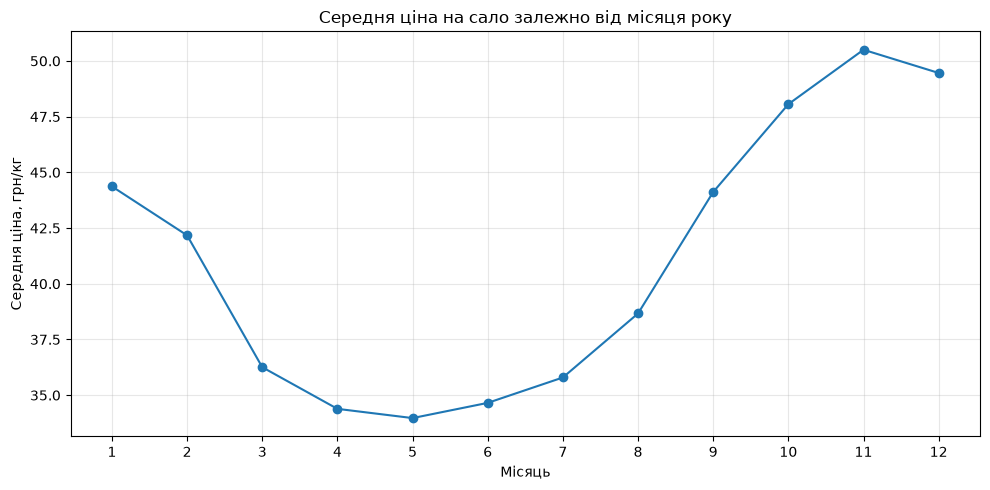

In [5]:
import matplotlib.pyplot as plt
# 1. Динаміка ціни в часі
plt.figure(figsize=(12,5))
plt.plot(s.index,s.values, marker='o', markersize=3)
plt.title('Динаміка роздрібної ціни на сало, 2014–2017')
plt.xlabel('Дата')
plt.ylabel('Ціна, грн/кг')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# 2. Середня ціна за кожен рік
yearly_mean = s.groupby(s.index.year).mean()
plt.figure(figsize=(8, 5))
plt.bar(yearly_mean.index.astype(str), yearly_mean.values)
plt.title('Середня ціна на сало за роками')
plt.xlabel('Рік')
plt.ylabel('Середня ціна, грн/кг')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
# 3. Cередня ціна за кожен місяць
monthly_mean = s.groupby(s.index.month).mean()
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_mean.index, monthly_mean.values,
    marker='o'
)
plt.xticks(range(1, 13))
plt.title('Середня ціна на сало залежно від місяця року')
plt.xlabel('Місяць')
plt.ylabel('Середня ціна, грн/кг')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Висновок до завдання 3:**
Є 3 графіки: ціна на сало протягом всього періоду, середня ціна за роками та середня ціна залежно від місяця року.
Не очікував такий великий сплеск в ціні після липня 2017 року.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

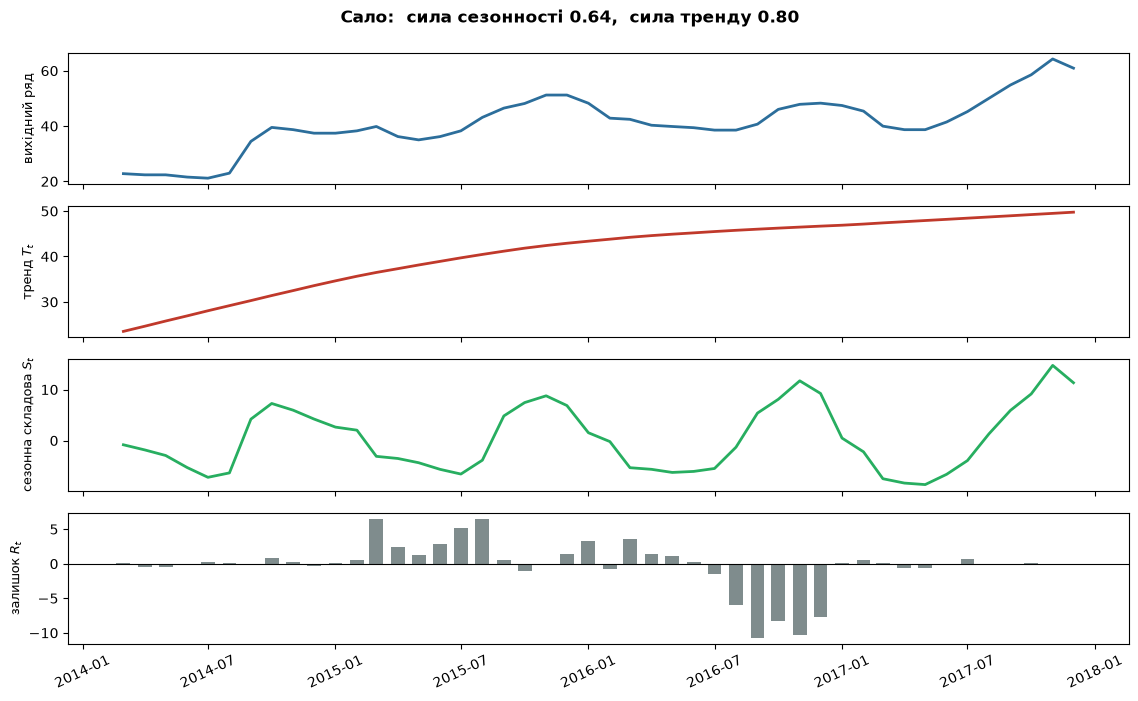

In [6]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL
res=STL(s, period=12, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(11.5, 7), sharex=True)
for ax, data, label, c in zip(
        axes,
        [s, res.trend, res.seasonal, res.resid],
        ['вихідний ряд', 'тренд $T_t$', 'сезонна складова $S_t$', 'залишок $R_t$'],
        ['#2C6E9B', '#C0392B', '#27AE60', '#7F8C8D']):
    if label.startswith('залишок'):
        ax.bar(data.index, data.values, width=20, color=c)
        ax.axhline(0, color='k', lw=.8)
    else:
        ax.plot(data.index, data.values, lw=2, color=c)
    ax.set_ylabel(label, fontsize=9)
Fs = max(0, 1 - res.resid.var()/(res.seasonal + res.resid).var())
Ft = max(0, 1 - res.resid.var()/(res.trend   + res.resid).var())
fig.suptitle(f'Сало:  сила сезонності {Fs:.2f},  сила тренду {Ft:.2f}',
             fontweight='bold', y=.995)
axes[-1].tick_params(axis='x', labelrotation=25)
plt.tight_layout(); plt.show()

**Висновок до завдання 4:**

В моєму ряді сезонність присутня (Fs>0.3)

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

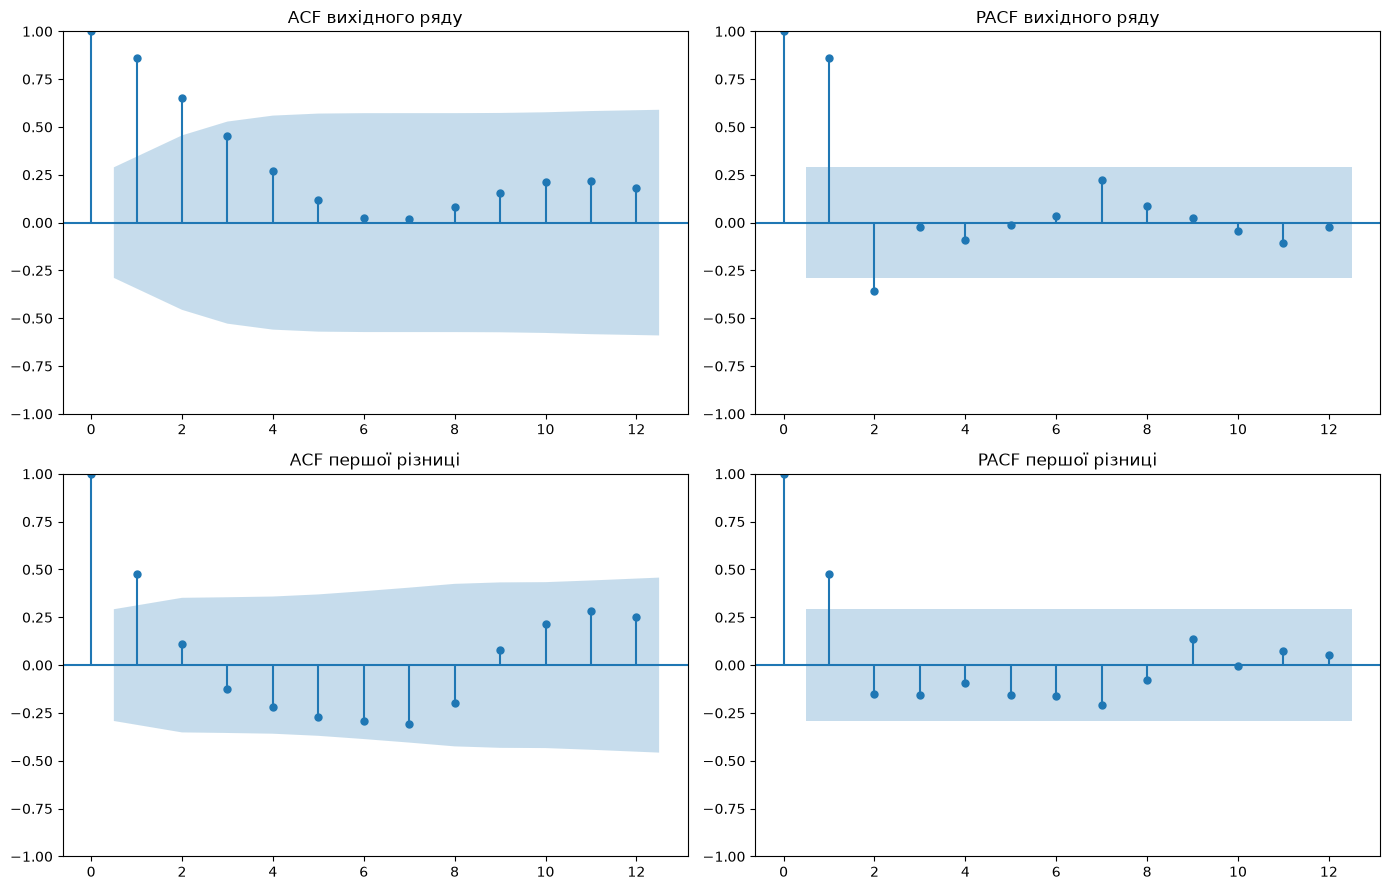

               ADF p-value  KPSS p-value
Вихідний ряд        0.1385        0.0128
Перша різниця       0.0001        0.1000


C:\Users\JustDector\AppData\Local\Temp\ipykernel_22608\2614389506.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result=adfuller(series, regression='c', autolag='AIC')
C:\Users\JustDector\AppData\Local\Temp\ipykernel_22608\2614389506.py:19: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result=kpss(series, regression='c

In [21]:
# Завдання 5. Стаціонарність
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

s_diff=s.diff().dropna()
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_acf(s, lags=12, ax=axes[0, 0])
axes[0, 0].set_title('ACF вихідного ряду')
plot_pacf(s, lags=12, ax=axes[0, 1], method='ywm')
axes[0, 1].set_title('PACF вихідного ряду')
plot_acf(s_diff, lags=12, ax=axes[1, 0])
axes[1, 0].set_title('ACF першої різниці')
plot_pacf(s_diff, lags=12, ax=axes[1, 1], method='ywm')
axes[1, 1].set_title('PACF першої різниці')
plt.tight_layout()
plt.show()
def run_tests(series):
    adf_result=adfuller(series, regression='c', autolag='AIC')
    kpss_result=kpss(series, regression='c', nlags='auto')
    return {
        'ADF p-value': adf_result[1],
        'KPSS p-value': kpss_result[1]
    }

results=pd.DataFrame(
    {
        'Вихідний ряд': run_tests(s),
        'Перша різниця': run_tests(s_diff)
    }
).T

print(results.round(4))

**Висновок до завдання 5:**
Вихідний ряд - нестаціонарний. Після диференціювання ряд стає стаціонарним.
У двох випадках тести не суперечать.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [8]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

HORIZON = 3
N_FOLDS = 7
m = 12
ALPHA = 0.25

series = s.astype(float).sort_index().interpolate().dropna()
methods = ['наївний', 'сезонний наївний', 'середнє', 'дрейф']

def metrics(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    mask = np.isfinite(actual) & np.isfinite(pred)
    actual, pred = actual[mask], pred[mask]
    nonzero = actual != 0
    mape = (
        np.mean(np.abs((actual[nonzero] - pred[nonzero])
                       / actual[nonzero])) * 100
        if nonzero.any() else np.nan
    )
    return {
        'MAE': mean_absolute_error(actual, pred),
        'RMSE': np.sqrt(mean_squared_error(actual, pred)),
        'MAPE': mape
    }


def forecast(train, method, horizon=HORIZON):
    n = len(train)
    if method == 'наївний':
        return np.repeat(train.iloc[-1], horizon)
    if method == 'сезонний наївний':
        return np.array([
            train.iloc[-m + h % m] for h in range(horizon)
        ])
    if method == 'середнє':
        return np.repeat(train.mean(), horizon)
    if method == 'дрейф':
        slope = ((train.iloc[-1] - train.iloc[0]) / (n - 1)
                 if n > 1 else 0)
        return np.array([
            train.iloc[-1] + (h + 1) * slope
            for h in range(horizon)
        ])
n = len(series)
initial_size = n - N_FOLDS * HORIZON
if initial_size < m:
    raise ValueError('Недостатньо даних для 7 фолдів.')
actual_cv = []
predictions_cv = {method: [] for method in methods}

for fold in range(N_FOLDS):
    end = initial_size + fold * HORIZON
    train = series.iloc[:end]
    test = series.iloc[end:end + HORIZON]

    actual_cv.extend(test.to_numpy())

    for method in methods:
        predictions_cv[method].extend(
            forecast(train, method, len(test))
        )

cv_results = pd.DataFrame({
    method: metrics(actual_cv, predictions_cv[method])
    for method in methods
}).T

print('Ретроспективна перевірка:')
display(cv_results.round(3).sort_values('MAE'))
train_idx, test_idx = train_test_split(
    np.arange(n), test_size=ALPHA, random_state=42
)

train = series.iloc[train_idx].sort_index()
test = series.iloc[test_idx].sort_index()


def random_split_forecast(train, test, method):
    result = []
    for date in test.index:
        if method == 'наївний':
            past = train[train.index < date]
            pred = past.iloc[-1] if len(past) else train.iloc[0]

        elif method == 'сезонний наївний':
            target_date = date - pd.DateOffset(months=m)
            if target_date in train.index:
                pred = train.loc[target_date]
            else:
                same_month = train[train.index.month == date.month]
                pred = same_month.iloc[-1] if len(same_month) else train.mean()

        elif method == 'середнє':
            pred = train.mean()

        elif method == 'дрейф':
            slope = (
                (train.iloc[-1] - train.iloc[0])
                / ((train.index[-1] - train.index[0]).days)
                if (train.index[-1] - train.index[0]).days != 0 else 0
            )
            pred = train.iloc[-1] + slope * (date - train.index[-1]).days
        result.append(pred)
    return np.asarray(result)


random_results = pd.DataFrame({
    method: metrics(
        test.to_numpy(),
        random_split_forecast(train, test, method)
    )
    for method in methods
}).T

print('Випадковий поділ 75/25:')
display(random_results.round(3).sort_values('MAE'))

comparison = pd.DataFrame(index=methods)

for metric in ['MAE', 'RMSE', 'MAPE']:
    comparison[f'{metric} — рухомий початок'] = cv_results[metric]
    comparison[f'{metric} — випадковий поділ'] = random_results[metric]
    comparison[f'{metric} — відношення'] = (
        random_results[metric] / cv_results[metric].replace(0, np.nan)
    )

print('Порівняння метрик:')
display(comparison.round(3))

best = cv_results['MAE'].idxmin()
print(f'Найкращий базис за MAE: {best}')


Ретроспективна перевірка:


,MAE,RMSE,MAPE
дрейф,4.357,5.322,9.301
наївний,4.374,5.564,9.018
сезонний наївний,5.514,7.284,11.045
середнє,7.928,10.617,15.393


Випадковий поділ 75/25:


,MAE,RMSE,MAPE
наївний,3.102,4.290,7.788
дрейф,6.156,6.966,16.358
середнє,7.527,11.089,24.034
сезонний наївний,11.036,13.374,34.124


Порівняння метрик:


,MAE — рухомий початок,MAE — випадковий поділ,MAE — відношення,RMSE — рухомий початок,RMSE — випадковий поділ,RMSE — відношення,MAPE — рухомий початок,MAPE — випадковий поділ,MAPE — відношення
наївний,4.374,3.102,0.709,5.564,4.290,0.771,9.018,7.788,0.864
сезонний наївний,5.514,11.036,2.001,7.284,13.374,1.836,11.045,34.124,3.090
середнє,7.928,7.527,0.949,10.617,11.089,1.044,15.393,24.034,1.561
дрейф,4.357,6.156,1.413,5.322,6.966,1.309,9.301,16.358,1.759


Найкращий базис за MAE: дрейф


**Висновок до завдання 6:**

На мою думку, найкращий базис тут є дрейф, бо сила тренду - 0.8, а дрейф підходить для прогнозів з трендом.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

Ретроспективна перевірка: 7 фолдів по 3 кроки


,MAE,RMSE,MAPE
"ARIMA(1,1,1)",3.905,4.744,8.436
Дрейф,4.357,5.322,9.301



ARIMA порівняно з дрейфом (менше — краще):
MAE: 0.896x від значення дрейфу
RMSE: 0.891x від значення дрейфу
MAPE: 0.907x від значення дрейфу


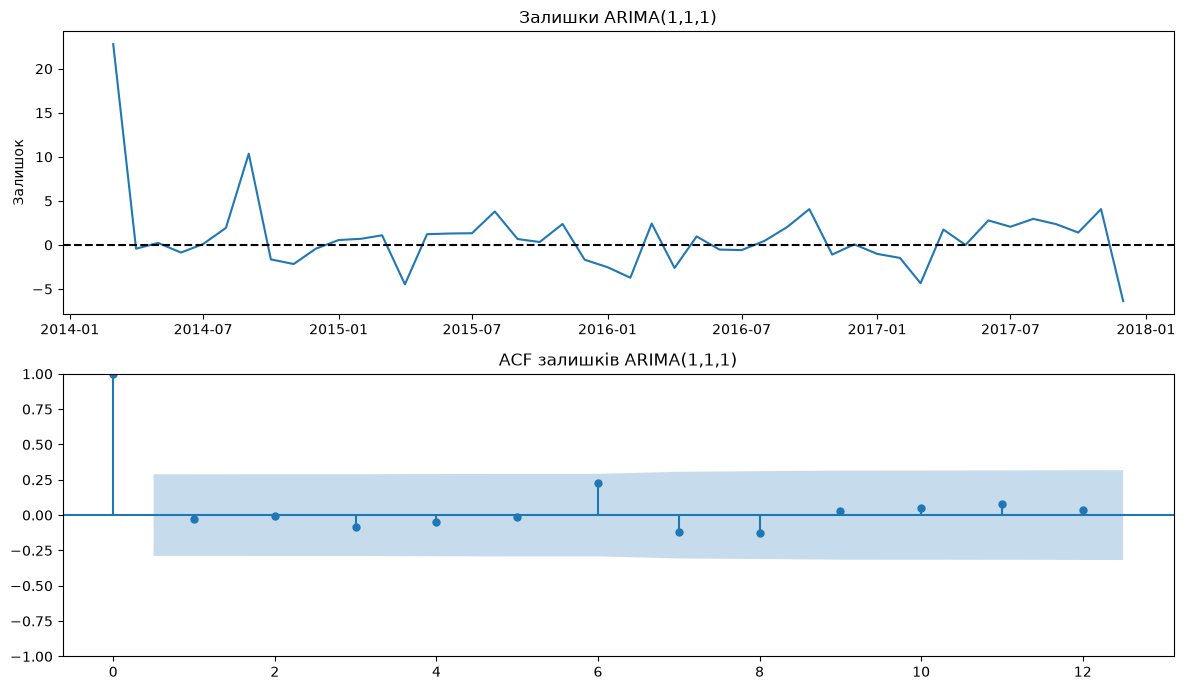

Тест Льюнга—Бокса:


,lb_stat,lb_pvalue
6,3.4892,0.7454


Висновок: недостатньо підстав стверджувати, що залишилася автокореляція.


In [9]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
series = s.astype(float).sort_index().interpolate().dropna()
n = len(series)
initial_size = n - N_FOLDS * HORIZON

if initial_size < m:
    raise ValueError('Недостатньо спостережень для заданих фолдів.')

actual_cv = []
pred_arima = []
pred_drift = []

for fold in range(N_FOLDS):
    end = initial_size + fold * HORIZON
    train = series.iloc[:end]
    test = series.iloc[end:end + HORIZON]
    model = ARIMA(train, order=(1, 1, 1))
    fitted = model.fit()
    forecast_arima = fitted.forecast(steps=len(test))
    slope = (
        (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
        if len(train) > 1 else 0
    )
    forecast_drift = np.array([
        train.iloc[-1] + h * slope
        for h in range(1, len(test) + 1)
    ])

    actual_cv.extend(test.to_numpy())
    pred_arima.extend(np.asarray(forecast_arima))
    pred_drift.extend(forecast_drift)


results = pd.DataFrame({
    'ARIMA(1,1,1)': metrics(actual_cv, pred_arima),
    'Дрейф': metrics(actual_cv, pred_drift)
}).T

print('Ретроспективна перевірка: 7 фолдів по 3 кроки')
display(results.round(3))

print('\nARIMA порівняно з дрейфом (менше — краще):')
for metric in ['MAE', 'RMSE', 'MAPE']:
    arima_value = results.loc['ARIMA(1,1,1)', metric]
    drift_value = results.loc['Дрейф', metric]
    ratio = arima_value / drift_value if drift_value != 0 else np.nan

    print(f'{metric}: {ratio:.3f}x від значення дрейфу')
final_model = ARIMA(series, order=(1, 1, 1)).fit()
residuals = pd.Series(
    final_model.resid,
    index=series.index
).dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(residuals.index, residuals.values)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set_title('Залишки ARIMA(1,1,1)')
axes[0].set_ylabel('Залишок')

plot_acf(residuals, lags=12, ax=axes[1])
axes[1].set_title('ACF залишків ARIMA(1,1,1)')

plt.tight_layout()
plt.show()

lb = acorr_ljungbox(residuals, lags=[6], return_df=True)
print('Тест Льюнга—Бокса:')
display(lb.round(4))

p_value = lb['lb_pvalue'].iloc[0]

if p_value < 0.05:
    print('Висновок: залишилася статистично значуща автокореляція.')
else:
    print('Висновок: недостатньо підстав стверджувати, що залишилася автокореляція.')

**Висновок до завдання 7:**

Залишки моделі можемо назвати білим шумом, тобто вони є незалежні та випадкові.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Дата зміни рівня: 2015-08-01
t-статистика: -6.285
p-value без корекції: 0.00000
Середнє до зміни: 32.027
Середнє після зміни: 46.160
Кількість місяців до: 17
Кількість місяців після: 29
Висновок: зсув статистично значущий (після корекції).


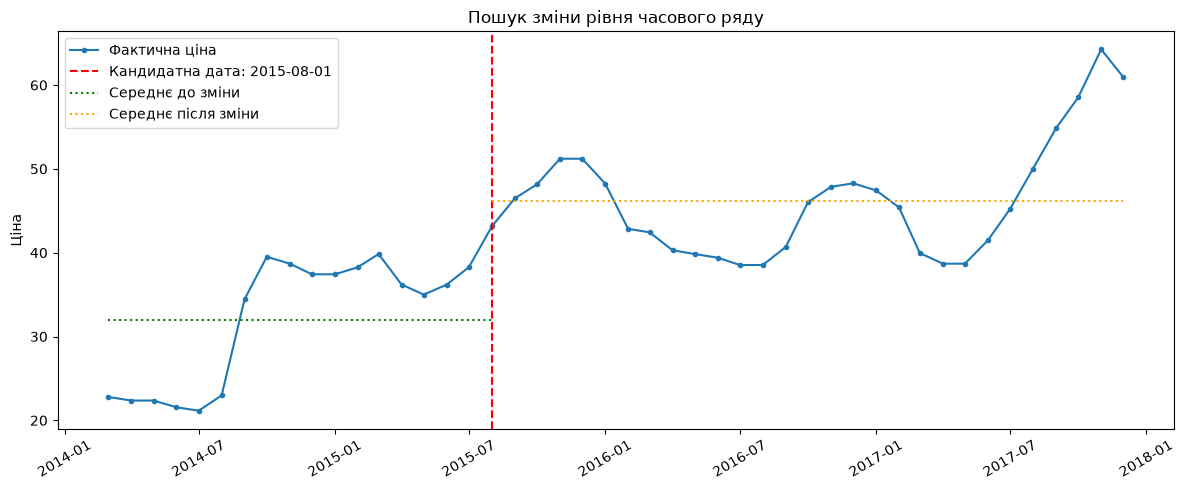

In [43]:
# Завдання 8. Точка зміни режиму
from scipy.stats import ttest_ind
series = s.astype(float).sort_index().dropna()
min_segment=12
results=[]
for i in range(min_segment, len(series) - min_segment + 1):
    before = series.iloc[:i]
    after = series.iloc[i:]
    t_stat, p_value = ttest_ind(
        before, after,
        equal_var=False
    )

    results.append({
        'date': series.index[i],
        't_stat': t_stat,
        'abs_t': abs(t_stat),
        'p_value': p_value,
        'mean_before': before.mean(),
        'mean_after': after.mean(),
        'n_before': len(before),
        'n_after': len(after)
    })

results = pd.DataFrame(results)
best = results.loc[results['abs_t'].idxmax()]
n_tests = len(results)

print(f"Дата зміни рівня: {best['date'].date()}")
print(f"t-статистика: {best['t_stat']:.3f}")
print(f"p-value без корекції: {best['p_value']:.5f}")
print(f"Середнє до зміни: {best['mean_before']:.3f}")
print(f"Середнє після зміни: {best['mean_after']:.3f}")
print(f"Кількість місяців до: {best['n_before']}")
print(f"Кількість місяців після: {best['n_after']}")

if p_adjusted < 0.05:
    print("Висновок: зсув статистично значущий (після корекції).")
else:
    print("Висновок: зсув не є статистично значущим після корекції.")
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(series.index, series.values, marker='o', markersize=3,
        label='Фактична ціна')

ax.axvline(
    best['date'], color='red', linestyle='--',
    label=f"Кандидатна дата: {best['date'].date()}"
)

ax.hlines(
    best['mean_before'],
    xmin=series.index[0], xmax=best['date'],
    colors='green', linestyles=':',
    label='Середнє до зміни'
)

ax.hlines(
    best['mean_after'],
    xmin=best['date'], xmax=series.index[-1],
    colors='orange', linestyles=':',
    label='Середнє після зміни'
)

ax.set_title('Пошук зміни рівня часового ряду')
ax.set_ylabel('Ціна')
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Висновок до завдання 8:**

Сезонні сплески повторюються та мають одну амплітуду, ця точка зазвичай одноразова і має вищий або такий самий сплеск, як і сезонний.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

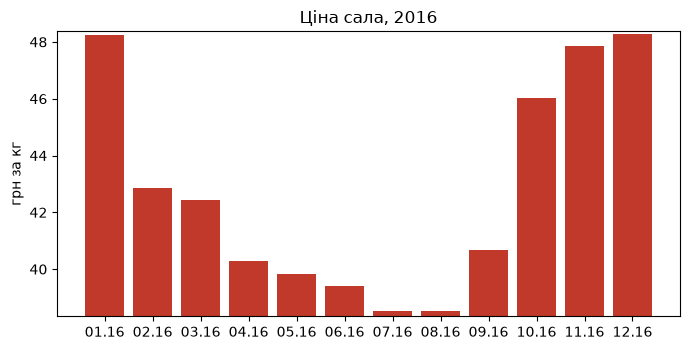

In [42]:
# Завдання 9. Рецензія на чужий аналіз
w = s['2016-01':'2016-12']
fig, ax = plt.subplots(figsize=(7,3.6))
ax.bar([d.strftime('%m.%y') for d in w.index], w.values, color='#C0392B')
ax.set_ylim(w.min()*0.995, w.max()*1.002)
ax.set_ylabel('грн за кг'); ax.set_title('Ціна сала, 2016')
plt.tight_layout(); plt.show()

**Висновок до завдання 9:**

Розділ 1: неправильно перевіряємо пропущені значення, в цьому випадку втрачаємо одне вимірювання.
Розділ 2: не можемо просто дивитись на скільки зросла ціна за певний час, потрібно бачити як вона зростає і чому
Розділ 4: ціни на гречку і так будуть приблизно одинакові для різних областей, можемо порівняти різні товари одної області
Розділ 7: береться середнє за весь часовий період ряду, потрібно дивитись на різкі сплески в значеннях.
Розділ 8: невідхиляння нульової гіпотези не означає, що ряд стаціонарний, а також необов'язково застосовувати подвійне диференціювання, результати ADF потрібно порівняти ще з результатами KPSS
Розділ 9: по графіку бачимо, що ціна буде зменшуватись
Розділ 10: потрібно розглядати весь 2016 рік
Для виправлення першого розділу застосовуємо лінійну інтерполяцію, якщо це можливо.
Для другого розділу дивимось на графік цін протягом періоду, який ми розглядаємо.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [ ]:
# Завдання 10. Експорт ряду для Orange

grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
orange_df = pd.DataFrame({
    'date': grid.strftime('%Y-%m-%d'),
    'price': s.reindex(grid).to_numpy()
})
assert len(orange_df) == 46, f"Очікується 46 рядків, отримано {len(orange_df)}"
assert list(orange_df.columns) == ['date', 'price']
assert orange_df.notna().all().all(), "У даних є пропущені значення!"
assert pd.api.types.is_numeric_dtype(orange_df['price']), "Ціна має бути числовою"

orange_df.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')
check_df = pd.read_csv('ряд_для_orange.csv', encoding='utf-8')

assert len(check_df) == 46
assert list(check_df.columns) == ['date', 'price']
assert check_df.notna().all().all()
assert check_df['date'].str.fullmatch(r'\d{4}-\d{2}-\d{2}').all()
print("Файл ряд_для_orange.csv успішно створено.")
print(f"Кількість рядків даних: {len(check_df)}")
print(f"Кількість порожніх значень: {check_df.isna().sum().sum()}")
print(f"Дати: від {check_df['date'].iloc[0]} до {check_df['date'].iloc[-1]}")
print(check_df.head())

Файл ряд_для_orange.csv успішно створено.
Кількість рядків даних: 46
Кількість порожніх значень: 0
Дати: від 2014-03-01 до 2017-12-01
         date    price
0  2014-03-01  22.7867
1  2014-04-01  22.3600
2  2014-05-01  22.3600
3  2014-06-01  21.5533
4  2014-07-01  21.1500


**Висновок до завдання 10:**

Створений файл готовий до використання в Orange.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

C:\Users\JustDector\AppData\Local\Temp\ipykernel_22608\3621602507.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


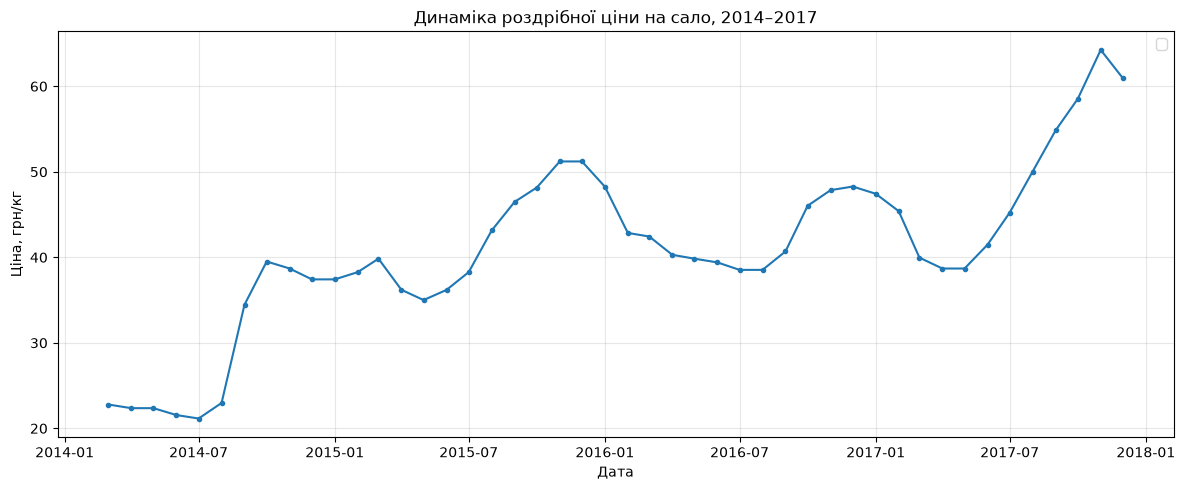

In [18]:
# Завдання 11. Потік опрацювання даних
plt.figure(figsize=(12,5))
plt.plot(s.index,s.values, marker='o', markersize=3)
plt.title('Динаміка роздрібної ціни на сало, 2014–2017')
plt.xlabel('Дата')
plt.ylabel('Ціна, грн/кг')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Висновок до завдання 11:**
Графіки збігаються.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

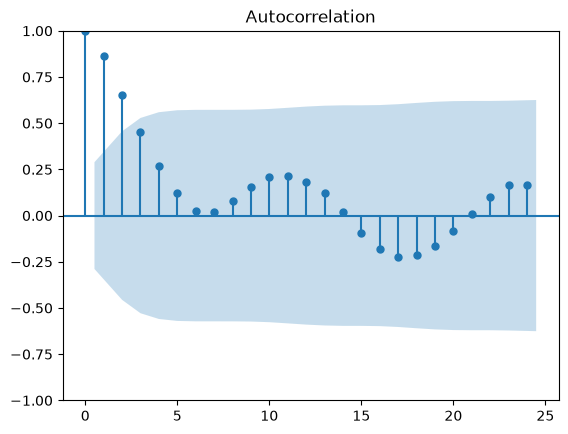

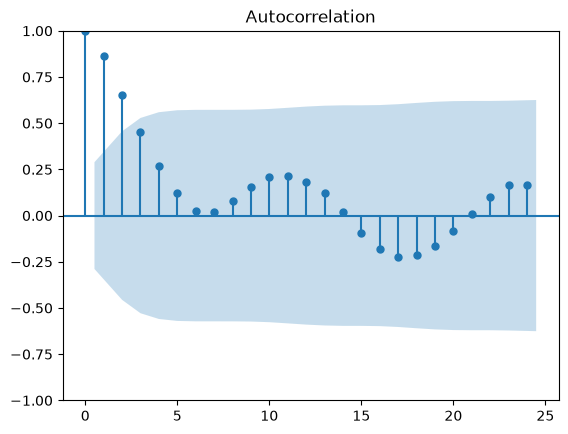

In [27]:
# Завдання 12. Автокореляція та диференціювання
plot_acf(s, lags=24)

**Висновок до завдання 12:**

Значущі лаги присутні.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

**Висновок до завдання 13:**

￼ Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations.
в нас замалий розмір ряду для 20 на 3 (потрібно 60, а рядків 46)
Orange перевіряє спочатку довші відрізки, і робить їх коротшими


## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [39]:
# Завдання 14. Чому числа не збігаються
def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    errors = y_true - y_pred

    rmse = np.sqrt(np.mean(errors ** 2))
    mae = np.mean(np.abs(errors))

    nonzero = y_true != 0
    mape = 100 * np.mean(
        np.abs(errors[nonzero] / y_true[nonzero])
    )

    actual_diff = np.diff(y_true)
    predicted_diff = np.diff(y_pred)

    pocid = 100 * np.mean(
        (actual_diff * predicted_diff) > 0
    )

    return {
        "RMSE": rmse,
        "MAE": mae,
        "MAPE": mape,
        "POCID": pocid
    }

n_folds = 7
horizon = 3
y_true_all = []
y_pred_all = []

for fold in range(n_folds):
    test_end = len(s) - fold * horizon
    test_start = test_end - horizon

    train = s.iloc[:test_start]
    test = s.iloc[test_start:test_end]

    model = ARIMA(train, order=(1, 1, 1))
    fitted = model.fit()
    forecast = fitted.forecast(steps=horizon)

    y_true_all.extend(test.to_numpy())
    y_pred_all.extend(np.asarray(forecast))

orange_val = {
    "RMSE": 4.744,
    "MAE": 3.150,
    "MAPE": 0.085,
    "POCID": 45.0
}

python_val = calculate_metrics(y_true_all, y_pred_all)
orange_val["MAPE"] *= 100

print(f"{'Метрика':<10} {'Orange':>12} {'Python':>12} {'Різниця':>12}")

for metric in orange_val:
    orange = orange_val[metric]
    python = python_val[metric]
    difference = python - orange

    print(
        f"{metric:<10} {orange:>12.3f} "
        f"{python:>12.3f} {difference:>12.3f}"
    )

Метрика          Orange       Python      Різниця
RMSE              4.744        4.744       -0.000
MAE               3.150        3.905        0.755
MAPE              8.500        8.436       -0.064
POCID            45.000       45.000        0.000


**Висновок до завдання 14:**
потрібно перевіряти, що значення означають, а також перевіряти, який формат результату.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [40]:
# Завдання 15. Матриця напрямку зміни

n_folds = 7
horizon = 3
actual_up_pred_up = 0
actual_up_pred_down = 0
actual_down_pred_up = 0
actual_down_pred_down = 0

correct = 0
total = 0

for fold in range(n_folds):
    test_end = len(s) - fold * horizon
    test_start = test_end - horizon

    train = s.iloc[:test_start]
    test = s.iloc[test_start:test_end]

    fitted = ARIMA(train, order=(1, 1, 1)).fit()
    forecast = np.asarray(fitted.forecast(steps=horizon))
    actual = test.to_numpy()
    previous_actual = float(train.iloc[-1])

    for real_price, predicted_price in zip(actual, forecast):
        actual_change = real_price - previous_actual
        predicted_change = predicted_price - previous_actual
        if actual_change != 0 and predicted_change != 0:
            if actual_change > 0 and predicted_change > 0:
                actual_up_pred_up += 1
                correct += 1
            elif actual_change > 0 and predicted_change < 0:
                actual_up_pred_down += 1
            elif actual_change < 0 and predicted_change > 0:
                actual_down_pred_up += 1
            else:
                actual_down_pred_down += 1
                correct += 1

            total += 1
        previous_actual = float(real_price)

matrix = pd.DataFrame(
    [
        [actual_up_pred_up, actual_up_pred_down],
        [actual_down_pred_up, actual_down_pred_down]
    ],
    index=["Фактично зросла", "Фактично впала"],
    columns=["Модель: зросла", "Модель: впала"]
)

print("Матриця напрямків:")
print(matrix)

pocid_python = 100 * correct / total if total else float("nan")

print(f"\nКількість врахованих прогнозів: {total}")
print(f"Правильних прогнозів напрямку: {correct}")
print(f"POCID Python: {pocid_python:.2f}%")
print("POCID Orange: 45.00%")
print(f"Різниця: {pocid_python - 45.0:.2f} процентного пункту")

Матриця напрямків:
                 Модель: зросла  Модель: впала
Фактично зросла               4              6
Фактично впала                6              3

Кількість врахованих прогнозів: 19
Правильних прогнозів напрямку: 7
POCID Python: 36.84%
POCID Orange: 45.00%
Різниця: -8.16 процентного пункту


**Висновок до завдання 15:**

Модель не дуже корисна для таких передбачень (менше половини правильних прогнозів)

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

В моєму ряді присутня сезонність. Визначена сила сезонності - 0.64, що є вище, ніж 0.3 (при перевищенні якого вважаємо, що сезонність присутня)
Щодо методів прогнозування мала перевага є в методу дрейфу над наївним методом, але не за всіма метриками. Але все одно обираю найкращий як дрейф, бо цей прогноз враховує історичний тренд, а сила тренду нашого ряду - 0.8.
Точка зміни режиму - серпень 2015, єдине посилання на таку можливу зміну - сутички після Закону про внесення змін до Конституції України (щодо децентралізації влади)
Вони можуть здаватись як однакові метрики, але маємо звернути увагу на що означають абревіатури. Ми визначали mean squared error, а в Orange це median squared error.
З таки рядом складно створити модель для прогнозу, вказаного в останньому завданні.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | ChatGPT |
| Для яких саме завдань | 5-8,15 |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | в основному код, деколи пояснення |
| Що ви змінили у згенерованому результаті й чому | якщо пояснення, то переписав своїми словами після перечитування |
| Що з отриманого ви **перевірили самостійно** і яким способом | побудову графіків, отримані значення |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | ні |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________